# Assignment 2 - Bruno Cavagnaro

## Question 1

1. (10 points) Show that the ridge regression estimates can be obtained by ordinary least squares regression on an augmented data set. We augment the centered matrix X with p additional rows √λ I, and augment y with p zeros. By introducing artificial data having response value zero, the fitting procedure is forced to shrink the coefficients toward zero. This is related to the idea of hints due to Abu-Mostafa (1995), where model constraints are implemented by adding artificial data examples that satisfy them.

### Answer Question 1: Ridge as OLS on augmented data

Let $X\in\mathbb R^{N\times p}$ be centered (so the intercept is estimated separately as $\hat\beta_0=\bar y$ and is not penalized), and define

$$
\tilde X=\begin{pmatrix}X\\ \sqrt{\lambda}\,I_p\end{pmatrix}\in\mathbb R^{(N+p)\times p},\qquad
\tilde y=\begin{pmatrix}y\\ \mathbf 0_p\end{pmatrix}\in\mathbb R^{N+p}.
$$

**Step 1 — the OLS criterion on the augmented data is the ridge criterion.**

$$
\|\tilde y-\tilde X\beta\|^2=\|y-X\beta\|^2+\|\mathbf 0_p-\sqrt\lambda\,I_p\beta\|^2=\sum_{i=1}^N (y_i-x_i^\top\beta)^2+\lambda\sum_{j=1}^p\beta_j^2 .
$$

This is exactly the penalized RSS that ridge regression minimizes, so both problems have the same minimizer.

**Step 2 — closed form.** The OLS solution on the augmented data is $\hat\beta=(\tilde X^\top\tilde X)^{-1}\tilde X^\top\tilde y$, and

$$
\tilde X^\top\tilde X = X^\top X+(\sqrt\lambda I_p)^\top(\sqrt\lambda I_p)=X^\top X+\lambda I_p,\qquad
\tilde X^\top\tilde y = X^\top y+\sqrt\lambda\, I_p\,\mathbf 0_p = X^\top y .
$$

Hence

$$
\hat\beta^{\text{OLS}}_{\text{aug}}=(X^\top X+\lambda I_p)^{-1}X^\top y=\hat\beta^{\text{ridge}}_\lambda .
$$

For $\lambda>0$, $\tilde X$ has full column rank $p$ (its last $p$ rows are $\sqrt\lambda I_p$), so $\tilde X^\top \tilde X$ is positive definite and the solution exists and is unique even if $p>N$ or $X$ is collinear.

**Interpretation.** Each artificial row $(\sqrt\lambda\, e_j^\top,\,0)$ is a "pseudo-observation" saying *"when only feature $j$ is switched on, the response is 0"*. Least squares tries to fit these points too, which pulls every $\beta_j$ toward 0; the larger $\lambda$, the more weight these hints carry (Abu-Mostafa, 1995).

**Remark on the intercept.** The augmentation must not touch $\beta_0$: either fit the augmented OLS *without* an intercept on centered $X$ and $y$ (then $\hat\beta_0=\bar y$), or add a column of ones to $X$ and a column of **zeros** in the $p$ artificial rows. Fitting an intercept on all $N+p$ rows would be wrong, because the artificial zeros would shift the mean.

In [1]:
import numpy as np
from sklearn.linear_model import Ridge

rng = np.random.default_rng(540)
N, p, lam = 100, 8, 3.7
X = rng.normal(size=(N,p)) @ rng.normal(size=(p,p)); y = 2 + X@rng.normal(size=p) + rng.normal(size=N)
Xc, yc = X - X.mean(0), y - y.mean()
b_ridge = np.linalg.solve(Xc.T@Xc + lam*np.eye(p), Xc.T@yc)
b_aug = np.linalg.lstsq(np.vstack([Xc, np.sqrt(lam)*np.eye(p)]), np.r_[yc, np.zeros(p)], rcond=None)[0]
print(np.abs(b_aug - b_ridge).max(), np.abs(b_aug - Ridge(alpha=lam).fit(X,y).coef_).max())  # ~1e-15

1.2434497875801753e-14 1.2947976024690888e-14


In [2]:
# Numerical check of Problem 1
import numpy as np
from sklearn.linear_model import Ridge, LinearRegression

N, p, lam = 100, 8, 3.7
X = rng.normal(size=(N, p)) @ rng.normal(size=(p, p))     # correlated predictors
y = 2 + X @ rng.normal(size=p) + rng.normal(size=N)
Xc, yc = X - X.mean(0), y - y.mean()

# (a) ridge closed form
beta_ridge = np.linalg.solve(Xc.T @ Xc + lam*np.eye(p), Xc.T @ yc)

# (b) OLS on the augmented data
X_aug = np.vstack([Xc, np.sqrt(lam)*np.eye(p)])
y_aug = np.concatenate([yc, np.zeros(p)])
beta_aug = np.linalg.lstsq(X_aug, y_aug, rcond=None)[0]

# (c) scikit-learn Ridge (fits the unpenalized intercept itself)
sk = Ridge(alpha=lam).fit(X, y)

print('ridge closed form :', beta_ridge)
print('augmented OLS     :', beta_aug)
print('sklearn Ridge     :', sk.coef_)
print('max |diff| aug vs ridge   =', np.abs(beta_aug - beta_ridge).max())
print('max |diff| aug vs sklearn =', np.abs(beta_aug - sk.coef_).max())
print('intercepts: ybar =', y.mean() - X.mean(0) @ beta_aug, ' sklearn =', sk.intercept_)

ridge closed form : [ 1.07472111 -0.71678089  0.96999201 -0.65250789 -0.61139648 -1.02065454
 -1.58407869  0.70784562]
augmented OLS     : [ 1.07472111 -0.71678089  0.96999201 -0.65250789 -0.61139648 -1.02065454
 -1.58407869  0.70784562]
sklearn Ridge     : [ 1.07472111 -0.71678089  0.96999201 -0.65250789 -0.61139648 -1.02065454
 -1.58407869  0.70784562]
max |diff| aug vs ridge   = 4.707345624410664e-14
max |diff| aug vs sklearn = 6.861178292183467e-14
intercepts: ybar = 1.9608356425451123  sklearn = 1.960835642545113


In [3]:
# Shrinkage path: augmented OLS reproduces ridge for every lambda, and ||beta|| shrinks toward 0
for lam_ in [0, 1, 10, 100, 1000, 1e5]:
    Xa = np.vstack([Xc, np.sqrt(lam_)*np.eye(p)]); ya = np.concatenate([yc, np.zeros(p)])
    b = np.linalg.lstsq(Xa, ya, rcond=None)[0]
    br = np.linalg.solve(Xc.T@Xc + lam_*np.eye(p), Xc.T@yc)
    print(f'lambda={lam_:>8g}  ||beta||={np.linalg.norm(b):9.4f}   max|aug-ridge|={np.abs(b-br).max():.1e}')

lambda=       0  ||beta||=   4.7805   max|aug-ridge|=8.0e-13
lambda=       1  ||beta||=   3.0968   max|aug-ridge|=2.1e-13
lambda=      10  ||beta||=   2.6474   max|aug-ridge|=2.1e-14
lambda=     100  ||beta||=   2.3182   max|aug-ridge|=1.9e-15
lambda=    1000  ||beta||=   1.2542   max|aug-ridge|=8.3e-16
lambda=  100000  ||beta||=   0.0278   max|aug-ridge|=2.3e-17


## Question 2

2. (30 points) Recall that a generative classifier estimates P(X, Y ) = P(Y )P(X|Y ), while a discriminative classifier directly estimates P(Y |X). Assume:

(a) Y is a boolean variable following a Bernoulli distribution, with parameter π = P(Y = 1) and thus P(Y = 0) = 1 − π. \
(b) X = (X1, . . . , Xp), where each attribute Xj is a continuous random variable. For each Xj, P(Xj|Y = k) is a Gaussian distribution N(µjk, σ2j), which does not depend on k. \
(c) For all i ̸= j, Xi and Xj are conditionally independent given Y . This us why this type of classifier is called “naive”.

## Answer Problem 2 — Gaussian naive Bayes vs. logistic regression

By Bayes' rule, and using conditional independence (assumption c),

$$
P(Y=1\mid X)=\frac{P(Y=1)P(X\mid Y=1)}{P(Y=1)P(X\mid Y=1)+P(Y=0)P(X\mid Y=0)}
=\frac{1}{1+\exp\!\Big(\ln\frac{1-\pi}{\pi}+\sum_{j=1}^p \ln\frac{P(X_j\mid Y=0)}{P(X_j\mid Y=1)}\Big)} .
$$

Equivalently, the log-odds are

$$
\eta(x)\equiv\ln\frac{P(Y=1\mid x)}{P(Y=0\mid x)}=\ln\frac{\pi}{1-\pi}+\sum_{j=1}^p\ln\frac{P(x_j\mid Y=1)}{P(x_j\mid Y=0)},\qquad P(Y=1\mid x)=\frac{1}{1+e^{-\eta(x)}} .
$$

Everything reduces to the per-feature log-likelihood ratio.

### Part 1

We say this is a specific class of Gaussian naive Bayes classifier because we have made an assumption that the standard derivation σj of P(Xj|Y = k) does not depend of k. This is not a general assumption for Gaussian naive Bayes classifiers. Show that the form of P(Y |X) derived from the assumptions of a specific class of Gaussian naive Bayes classifiers is precisely the form used by logistic regression. [10 points]

### (a) Shared variance $\sigma_j$ (does not depend on $k$)

$$
\ln\frac{P(x_j\mid Y=1)}{P(x_j\mid Y=0)}
=\ln\frac{\frac{1}{\sqrt{2\pi}\sigma_j}e^{-(x_j-\mu_{j1})^2/2\sigma_j^2}}{\frac{1}{\sqrt{2\pi}\sigma_j}e^{-(x_j-\mu_{j0})^2/2\sigma_j^2}}
=\frac{(x_j-\mu_{j0})^2-(x_j-\mu_{j1})^2}{2\sigma_j^2}.
$$

The normalizing constants cancel because $\sigma_j$ is common. Expanding the squares, the $x_j^2$ terms **cancel**:

$$
(x_j-\mu_{j0})^2-(x_j-\mu_{j1})^2 = 2x_j(\mu_{j1}-\mu_{j0})+\mu_{j0}^2-\mu_{j1}^2 ,
$$

so

$$
\ln\frac{P(x_j\mid Y=1)}{P(x_j\mid Y=0)}=\frac{\mu_{j1}-\mu_{j0}}{\sigma_j^2}\,x_j+\frac{\mu_{j0}^2-\mu_{j1}^2}{2\sigma_j^2}.
$$

Therefore

$$
\boxed{P(Y=1\mid X)=\frac{1}{1+\exp\!\big(-(w_0+\sum_{j=1}^p w_jX_j)\big)}}\quad\text{with}\quad
w_j=\frac{\mu_{j1}-\mu_{j0}}{\sigma_j^2},\qquad
w_0=\ln\frac{\pi}{1-\pi}+\sum_{j=1}^p\frac{\mu_{j0}^2-\mu_{j1}^2}{2\sigma_j^2}.
$$

This is precisely the logistic regression model: the log-odds are linear in $X$, and the decision boundary $w_0+w^\top x=0$ is a hyperplane. (Equivalently, $P(Y=0\mid X)=\exp(-\eta)/(1+\exp(-\eta))$; with the convention $P(Y=1|X)=1/(1+\exp(w_0+\sum w_jX_j))$ the weights simply change sign.)

The difference between the two classifiers is not the *form* but how the parameters are estimated: GNB estimates $(\pi,\mu_{jk},\sigma_j)$ by maximizing the joint likelihood $P(X,Y)$, while logistic regression estimates $(w_0,w)$ directly by maximizing the conditional likelihood $P(Y\mid X)$. When the GNB assumptions hold, both converge to the same classifier; when they fail, logistic regression is usually better asymptotically, while GNB converges faster with few samples (Ng & Jordan, 2002).

### Part 2

Next, let’s make our Gaussian naive Bayes classifiers a little more general by removing the assumption that the standard deviation σj of P(Xj|Y = k) does not depend of k. As a result, for each Xj, P(Xj|Y = k) is a Gaussian distribution N(µjk, σ2jk), where j = 1, . . . , p, k = 0, 1. Is the new form of P(Y |X) implied by this more general Gaussian naive Bayes classifier still the form used by logistic regression? Derive the new form of P(Y |X) to prove your answer. [10 points]

### (b) Class-specific variance $\sigma_{jk}$

Now the normalizing constants no longer cancel:

$$
\ln\frac{P(x_j\mid Y=1)}{P(x_j\mid Y=0)}
=\ln\frac{\sigma_{j0}}{\sigma_{j1}}-\frac{(x_j-\mu_{j1})^2}{2\sigma_{j1}^2}+\frac{(x_j-\mu_{j0})^2}{2\sigma_{j0}^2}.
$$

Expanding and collecting powers of $x_j$:

$$
=\underbrace{\Big(\frac{1}{2\sigma_{j0}^2}-\frac{1}{2\sigma_{j1}^2}\Big)}_{v_j}x_j^2
+\underbrace{\Big(\frac{\mu_{j1}}{\sigma_{j1}^2}-\frac{\mu_{j0}}{\sigma_{j0}^2}\Big)}_{w_j}x_j
+\underbrace{\ln\frac{\sigma_{j0}}{\sigma_{j1}}+\frac{\mu_{j0}^2}{2\sigma_{j0}^2}-\frac{\mu_{j1}^2}{2\sigma_{j1}^2}}_{c_j}.
$$

Hence

$$
\boxed{P(Y=1\mid X)=\frac{1}{1+\exp\!\Big(-\big(w_0+\sum_{j=1}^p w_jX_j+\sum_{j=1}^p v_jX_j^2\big)\Big)}},\qquad
w_0=\ln\frac{\pi}{1-\pi}+\sum_{j=1}^p c_j .
$$

**Answer: No.** In general $v_j\neq0$ whenever $\sigma_{j0}\neq\sigma_{j1}$, so the log-odds are a **quadratic** function of $X$ and the decision boundary is a quadric (an axis-aligned conic surface), not a hyperplane. This is not the (linear) logistic regression form in the original features. It reduces to the logistic form only in the special case $\sigma_{j0}=\sigma_{j1}$ for all $j$, where $v_j=0$ and we recover part (a). Note that it *is* a logistic regression in the expanded feature set $(X_1,\dots,X_p,X_1^2,\dots,X_p^2)$ without cross-product terms, i.e. a diagonal-covariance QDA.

### Part 3

Finally, you will implement the Gaussian Naive Bayes classifier and apply it to the spam data (https://hastie.su.domains/ElemStatLearn/data.html) in the textbook. [10 points]

### (c) Implementation on the spam data

The class **GaussianNaiveBayes** below is written from scratch with NumPy. Parameters are maximum-likelihood estimates:

- $\hat\pi=\frac1N\sum_i y_i$, $\hat\mu_{jk}$ = class mean of feature $j$.
- Class-specific variance: $\hat\sigma^2_{jk}$ = within-class variance of feature $j$.
- Shared variance: pooled within-class variance $\hat\sigma^2_j=\frac{1}{N-2}\sum_i (x_{ij}-\hat\mu_{j,y_i})^2$.

Predictions are computed in log-space (sum of log-densities), which avoids numerical underflow with 57 features. A tiny variance floor (as in scikit-learn's **var_smoothing**) prevents division by zero.

The code also checks numerically that the shared-variance model's posterior equals $\sigma(w_0+w^\top x)$ with the weights from (a), and that the class-specific model's posterior equals the quadratic-logistic form in (b).

In [4]:
import os, urllib.request
import numpy as np, pandas as pd

def download(url, fname):
    if not os.path.exists(fname):
        print('descargando', fname, '...')
        urllib.request.urlretrieve(url, fname)

# Archivos oficiales de ESL (incluye el split train/test del libro)
ESL = 'https://hastie.su.domains/ElemStatLearn/datasets/'

try:
    download(ESL + 'spam.data', 'spam.data')
    download(ESL + 'spam.traintest', 'spam.traintest')
    
except Exception as e:
    print('No se pudo bajar de ESL (', e, ') -> uso el espejo de GitHub')
    download('https://raw.githubusercontent.com/selva86/datasets/master/spam.csv', 'spam.csv')

def load_spam():
    if os.path.exists('spam.data'):                       # archivo oficial ESL (sin header)
        d = np.loadtxt('spam.data'); X, y = d[:, :-1], d[:, -1].astype(int)
    else:                                                 # espejo csv con header
        d = pd.read_csv('spam.csv'); y = d.iloc[:, -1].astype(int).values; X = d.iloc[:, :-1].values.astype(float)
    if os.path.exists('spam.traintest'):                  # indicador ESL: 1 = test
        test = np.loadtxt('spam.traintest').astype(bool)
    else:
        from sklearn.model_selection import train_test_split
        idx = np.arange(len(y))
        _, te_idx = train_test_split(idx, test_size=1536, stratify=y, random_state=SEED)
        test = np.isin(idx, te_idx)
    return X[~test], X[test], y[~test], y[test]

Xtr_s, Xte_s, ytr_s, yte_s = load_spam()
print('train', Xtr_s.shape, 'test', Xte_s.shape, ' spam rate train/test:', ytr_s.mean().round(3), yte_s.mean().round(3))

train (3065, 57) test (1536, 57)  spam rate train/test: 0.397 0.387


In [5]:
class GaussianNaiveBayes:
    # Gaussian naive Bayes, binary Y in {0,1}.
    # shared_var=True  -> sigma_j does not depend on k (part a)
    # shared_var=False -> sigma_jk depends on k        (part b, the usual GNB)
    def __init__(self, shared_var=False, var_smoothing=1e-9):
        self.shared_var, self.var_smoothing = shared_var, var_smoothing

    def fit(self, X, y):
        X, y = np.asarray(X, float), np.asarray(y, int)
        self.pi_ = y.mean()
        self.mu_ = np.vstack([X[y == k].mean(0) for k in (0, 1)])            # (2, p)
        if self.shared_var:
            resid = X - self.mu_[y]
            v = (resid**2).sum(0) / (len(y) - 2)                              # pooled variance
            self.var_ = np.vstack([v, v])
        else:
            self.var_ = np.vstack([X[y == k].var(0) for k in (0, 1)])         # MLE per class
        self.var_ = self.var_ + self.var_smoothing * X.var(0).max()
        return self

    def log_joint(self, X):                                                    # log P(Y=k) + log P(x|Y=k)
        X = np.asarray(X, float)
        prior = np.log([1 - self.pi_, self.pi_])
        return np.column_stack([prior[k] - 0.5*np.sum(np.log(2*np.pi*self.var_[k])
                                                      + (X - self.mu_[k])**2 / self.var_[k], axis=1)
                                for k in (0, 1)])

    def log_odds(self, X):
        L = self.log_joint(X); return L[:, 1] - L[:, 0]

    def predict_proba(self, X):
        return 1 / (1 + np.exp(-np.clip(self.log_odds(X), -700, 700)))

    def predict(self, X):
        return (self.log_odds(X) > 0).astype(int)

    # closed-form logistic parameters from the derivations
    def logistic_params(self):
        m0, m1 = self.mu_; s0, s1 = self.var_
        b0 = np.log(self.pi_ / (1 - self.pi_))
        if self.shared_var:                                                    # part (a)
            w = (m1 - m0) / s0
            w0 = b0 + np.sum((m0**2 - m1**2) / (2*s0))
            return w0, w, np.zeros_like(w)
        v = 1/(2*s0) - 1/(2*s1)                                                # part (b)
        w = m1/s1 - m0/s0
        w0 = b0 + np.sum(0.5*np.log(s0/s1) + m0**2/(2*s0) - m1**2/(2*s1))
        return w0, w, v

err = lambda m, X, y: np.mean(m.predict(X) != y)

In [6]:
from sklearn.naive_bayes import GaussianNB

sigmoid = lambda z: 1/(1+np.exp(-np.clip(z, -700, 700)))

for shared in (True, False):
    m = GaussianNaiveBayes(shared_var=shared).fit(Xtr_s, ytr_s)
    w0, w, v = m.logistic_params()
    p_formula = sigmoid(w0 + Xte_s @ w + (Xte_s**2) @ v)
    name = '(a) shared sigma_j   ' if shared else '(b) class-specific   '
    print(name, ' max|P_GNB(Y=1|x) - formula| =', f'{np.abs(p_formula - m.predict_proba(Xte_s)).max():.2e}',
          ' | max |v_j| =', f'{np.abs(v).max():.3g}')

# our class-specific GNB vs scikit-learn's GaussianNB (which uses sigma_jk)
ours = GaussianNaiveBayes(shared_var=False).fit(Xtr_s, ytr_s); sk = GaussianNB().fit(Xtr_s, ytr_s)
print('\nagreement of predictions with sklearn GaussianNB:', np.mean(ours.predict(Xte_s) == sk.predict(Xte_s)))
print('max |P_ours - P_sklearn| =', np.abs(ours.predict_proba(Xte_s) - sk.predict_proba(Xte_s)[:, 1]).max())

(a) shared sigma_j     max|P_GNB(Y=1|x) - formula| = 5.11e-14  | max |v_j| = 0
(b) class-specific     max|P_GNB(Y=1|x) - formula| = 2.66e-15  | max |v_j| = 1.32e+03

agreement of predictions with sklearn GaussianNB: 1.0
max |P_ours - P_sklearn| = 3.885780586188048e-15


The first check confirms the derivations: the shared-variance posterior is exactly $\sigma(w_0+w^\top x)$ (and all $v_j=0$), while the class-specific posterior needs the quadratic terms $v_jx_j^2$, which are clearly non-zero.

**Test error on the spam data.** The spam features are word/character frequencies: non-negative, mostly zero and extremely right-skewed, so the Gaussian assumption is badly violated. Following ESL (§4.4.2 and Ch. 9), I also report results with the transformation $\log(x+0.1)$, which makes the features closer to Gaussian. Logistic regression (the discriminative counterpart) is included for reference.

In [7]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

rows = []
for tname, f in [('raw features', lambda Z: Z), ('log(x + 0.1)', lambda Z: np.log(Z + 0.1))]:
    A, B = f(Xtr_s), f(Xte_s)
    for shared in (True, False):
        m = GaussianNaiveBayes(shared_var=shared).fit(A, ytr_s)
        rows.append([tname, 'GNB, shared sigma_j (linear = LR form)' if shared else 'GNB, class-specific sigma_jk (quadratic)',
                     err(m, A, ytr_s), err(m, B, yte_s)])
    lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)).fit(A, ytr_s)
    rows.append([tname, 'Logistic regression (discriminative)', 1-lr.score(A, ytr_s), 1-lr.score(B, yte_s)])

res_spam = pd.DataFrame(rows, columns=['features', 'model', 'train error', 'test error'])
res_spam.style.format({'train error': '{:.4f}', 'test error': '{:.4f}'}).hide(axis='index')

features,model,train error,test error
raw features,"GNB, shared sigma_j (linear = LR form)",0.1080,0.1198
raw features,"GNB, class-specific sigma_jk (quadratic)",0.1752,0.1836
raw features,Logistic regression (discriminative),0.0737,0.0755
log(x + 0.1),"GNB, shared sigma_j (linear = LR form)",0.0865,0.0938
log(x + 0.1),"GNB, class-specific sigma_jk (quadratic)",0.1635,0.1810
log(x + 0.1),Logistic regression (discriminative),0.0512,0.0586


In [8]:
# Confusion matrix + spam-specific error rates for the class-specific GNB (the standard GNB)
from sklearn.metrics import confusion_matrix

for tname, f in [('raw', lambda Z: Z), ('log(x+0.1)', lambda Z: np.log(Z + 0.1))]:
    m = GaussianNaiveBayes().fit(f(Xtr_s), ytr_s); pred = m.predict(f(Xte_s))
    cm = confusion_matrix(yte_s, pred)
    print(f'{tname:>11}: confusion matrix (rows=true email/spam, cols=predicted)\n{cm}')
    print(f'good email flagged as spam: {cm[0,1]/cm[0].sum():.3f}   spam missed: {cm[1,0]/cm[1].sum():.3f}\n')

        raw: confusion matrix (rows=true email/spam, cols=predicted)
[[685 256]
 [ 26 569]]
good email flagged as spam: 0.272   spam missed: 0.044

 log(x+0.1): confusion matrix (rows=true email/spam, cols=predicted)
[[702 239]
 [ 39 556]]
good email flagged as spam: 0.254   spam missed: 0.066



## Question 3

The MNIST dataset is a famous dataset in computer vision, which is available at https://www.kaggle.com/datasets/oddrationale/mnist-in-csv. The data files mnist train.csv and mnist test.csv contain gray-scale images of handdrawn digits, from 0 through 9. Each image is 28 pixels in height and 28 pixels in width, for a total of 784 pixels in total. Each pixel has a single pixel-value associated with it, indicating the lightness or darkness of that pixel, with higher numbers meaning darker. This pixel-value is an integer between 0 and 255, inclusive.

Let’s consider a binary classification problem by extracting data only for digits 5 and 8 from both training and test datasets. Analyze the MNIST data for digits 5 and 8 by using: \
— a single tree \
— bagging \
— random forest \
— boosting \

Compare their performances of these methods based on the misclassification error on the test dataset. You are not allowed to use any information from the 2 test dataset to produce the classifier. For each method, since we have the same training dataset and the same evaluation criteria, your score for this part will be based on your ranking among all students’ submissions.

## Answer Problem 3 — MNIST, digit 5 vs. digit 8: tree, bagging, random forest, boosting

1. Keep only digits 5 and 8 in both files; label $Y=1$ for digit 8, $Y=0$ for digit 5. Pixels are scaled to $[0,1]$.
2. **Feature engineering**, computed image by image (no information is shared across images, let alone with the test set):
   - *Deskewing*: each image is sheared so that its principal axis is vertical (moment-based, a classic MNIST preprocessing step). Handwriting slant is a major nuisance variation that axis-aligned tree splits model poorly.
   - *HOG features* (histogram of oriented gradients, 9 orientations, 7×7 cells): describe local stroke directions, which separate the open top of a 5 from the closed upper loop of an 8.
   - Final feature vector = 784 deskewed pixels + 324 HOG features = 1108 features.

   Whether to use these features is decided by **5-fold cross-validation on the training set** against raw pixels.
3. All hyperparameters are tuned by cross-validation or out-of-bag (OOB) error on the training set only.
4. The test set is used **once**, at the end, to report each final model's misclassification error.

In [9]:
import gzip

def build_mnist_csv():
    base = 'https://raw.githubusercontent.com/fgnt/mnist/master/'
    for f in ['train-images-idx3-ubyte.gz', 'train-labels-idx1-ubyte.gz',
              't10k-images-idx3-ubyte.gz', 't10k-labels-idx1-ubyte.gz']:
        download(base + f, f)
    read = lambda f, off: np.frombuffer(gzip.open(f).read(), np.uint8, offset=off)
    cols = [f'{i}x{j}' for i in range(1, 29) for j in range(1, 29)]
    for img, lab, out in [('train-images-idx3-ubyte.gz', 'train-labels-idx1-ubyte.gz', 'mnist_train.csv'),
                          ('t10k-images-idx3-ubyte.gz', 't10k-labels-idx1-ubyte.gz', 'mnist_test.csv')]:
        if not os.path.exists(out):
            df = pd.DataFrame(read(img, 16).reshape(-1, 784), columns=cols)
            df.insert(0, 'label', read(lab, 8)); df.to_csv(out, index=False)
            
build_mnist_csv()

In [10]:
import joblib, os, time
from scipy.ndimage import affine_transform
from skimage.feature import hog

os.makedirs('cache', exist_ok=True)

def cached(name, fn):
    # compute fn() once and store it in cache/<name>.joblib
    path = f'cache/{name}.joblib'
    if os.path.exists(path): return joblib.load(path)
    out = fn(); joblib.dump(out, path); return out

def deskew(img):
    # shear the image so that its pixel mass has zero row-column covariance (and re-center it)
    r, c = np.mgrid[:28, :28]; tot = img.sum()
    mr, mc = (r*img).sum()/tot, (c*img).sum()/tot
    alpha = ((r-mr)*(c-mc)*img).sum() / ((r-mr)**2*img).sum()
    A = np.array([[1, 0], [alpha, 1]])
    return affine_transform(img, A, offset=np.array([mr, mc]) - A @ np.array([14, 14]))

def make_features(X):
    D = np.array([deskew(x.reshape(28, 28)) for x in X])
    H = np.array([hog(d, orientations=9, pixels_per_cell=(7, 7), cells_per_block=(2, 2)) for d in D])
    return np.hstack([D.reshape(len(X), -1), H])

def load_mnist_58():
    tr = pd.read_csv('mnist_train.csv'); te = pd.read_csv('mnist_test.csv')
    tr = tr[tr['label'].isin([5, 8])]; te = te[te['label'].isin([5, 8])]
    Xtr = tr.drop(columns='label').values / 255.0; ytr = (tr['label'] == 8).astype(int).values
    Xte = te.drop(columns='label').values / 255.0; yte = (te['label'] == 8).astype(int).values
    return dict(Xtr=Xtr, Xte=Xte, ytr=ytr, yte=yte, Ftr=make_features(Xtr), Fte=make_features(Xte))

D = cached('mnist58', load_mnist_58)
Xtr_raw, Xte_raw, ytr, yte, Ftr, Fte = (D[k] for k in ['Xtr', 'Xte', 'ytr', 'yte', 'Ftr', 'Fte'])
print('train:', Xtr_raw.shape, ' share of 8s:', ytr.mean().round(3))
print('test :', Xte_raw.shape, ' share of 8s:', yte.mean().round(3))
print('engineered features:', Ftr.shape)

train: (11272, 784)  share of 8s: 0.519
test : (1866, 784)  share of 8s: 0.522
engineered features: (11272, 1108)


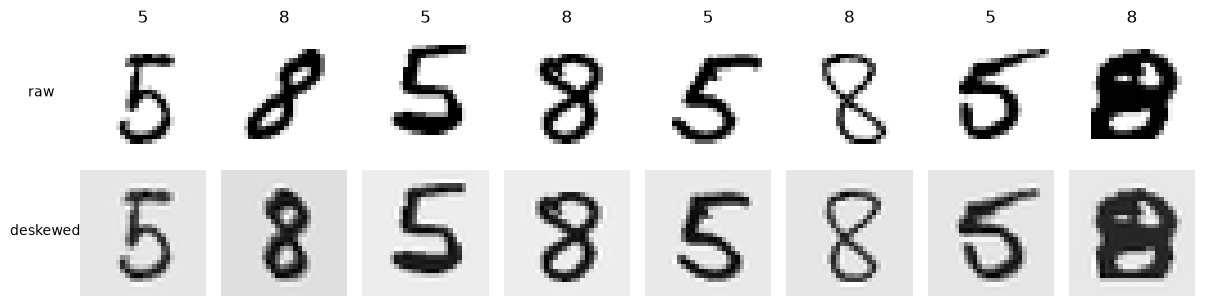

In [11]:
# Visual check of deskewing on a few training images
import matplotlib.pyplot as plt

fig, ax = plt.subplots(2, 8, figsize=(12, 3.2))

for i, k in enumerate(np.random.default_rng(1).choice(len(Xtr_raw), 8, replace=False)):
    ax[0, i].imshow(Xtr_raw[k].reshape(28, 28), cmap='gray_r'); ax[0, i].set_title(f'{5 + 3*ytr[k]}')
    ax[1, i].imshow(Ftr[k, :784].reshape(28, 28), cmap='gray_r')

for a in ax.ravel(): 
    a.axis('off')
ax[0, 0].text(-12, 14, 'raw', fontsize=10); ax[1, 0].text(-16, 14, 'deskewed', fontsize=10)
plt.tight_layout(); plt.show()

In [12]:
# Step 2 validation: raw pixels vs engineered features, 5-fold CV on TRAINING data only
from sklearn.model_selection import StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.ensemble import RandomForestClassifier

SEED = 540

cv = StratifiedKFold(5, shuffle=True, random_state=SEED)

def feature_cv():
    rf_probe = RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=SEED)
    out = {}
    for name, A in [('raw pixels', Xtr_raw), ('deskew + HOG', Ftr)]:
        s = cross_val_score(rf_probe, A, ytr, cv=cv, scoring='accuracy'); out[name] = (1 - s.mean(), s.std())
    return out
for name, (e, sd) in cached('feature_cv', feature_cv).items():
    print(f'{name:>13}: CV misclassification = {e:.4f} (+/- {sd:.4f})')

   raw pixels: CV misclassification = 0.0102 (+/- 0.0010)
 deskew + HOG: CV misclassification = 0.0067 (+/- 0.0013)


Cross-validation on the training data favors the engineered features, so all four methods use them from here on. Raw-pixel results are reported at the end for reference.

### 3.1 Single classification tree

A CART tree (scikit-learn **DecisionTreeClassifier**, Gini criterion) is grown fully and then **pruned by cost-complexity**. The pruning parameter $\alpha$ (**ccp_alpha**) is chosen by 5-fold CV among quantiles of the pruning path of the full tree.

In [13]:
from sklearn.tree import DecisionTreeClassifier

def tree_search():

    path = DecisionTreeClassifier(random_state=SEED).cost_complexity_pruning_path(Ftr, ytr)
    alphas = np.unique(np.quantile(path.ccp_alphas[:-1], [0, .7, .85, .9, .95, .98]))
    g = GridSearchCV(DecisionTreeClassifier(random_state=SEED), {'ccp_alpha': alphas, 'criterion': ['gini']},
                     cv=cv, scoring='accuracy', n_jobs=-1).fit(Ftr, ytr)
    return dict(best_params=g.best_params_, cv_error=1 - g.best_score_)

tree_res = cached('tree_cv', tree_search)
tree = cached('tree_model', lambda: DecisionTreeClassifier(random_state=SEED, **tree_res['best_params']).fit(Ftr, ytr))

print('best params:', tree_res['best_params'], f" CV error = {tree_res['cv_error']:.4f}",
      f' leaves = {tree.get_n_leaves()}, depth = {tree.get_depth()}')

best params: {'ccp_alpha': np.float64(0.0006993331159406389), 'criterion': 'gini'}  CV error = 0.0285  leaves = 33, depth = 7


### 3.2 Bagging

Bagging = $B$ fully grown, unpruned trees, each fit on a random resample of the training data, combined by averaging their votes and probabilities. Growing an exact (sorted-split) CART tree on 11,272 × 1108 features takes about 35 s on a single core, so I use LightGBM's histogram-based tree learner in random-forest mode:

- **boosting='rf'**: the trees are **averaged**, not boosted.
- **feature_fraction=1.0**: **every** feature is considered at every split, which is what distinguishes bagging from a random forest.
- **bagging_fraction=0.632**: each tree sees a random 63.2% subsample (without replacement). This is *subagging*, which behaves like the bootstrap (a bootstrap sample contains on average 63.2% distinct points; Bühlmann & Yu, 2002).
- **min_data_in_leaf=1**, **num_leaves=512**: trees are grown to purity. They end up with about 140 leaves, well below the cap.

The number of trees $B$ is read from the 5-fold CV error curve. Bagging does not overfit as $B$ grows, so we just need $B$ large enough for the curve to flatten.

In [15]:
import lightgbm as lgb

bag_params = dict(objective='binary', boosting='rf', bagging_fraction=0.632, bagging_freq=1, feature_fraction=1.0,
                  num_leaves=512, min_data_in_leaf=1, min_sum_hessian_in_leaf=0, max_bin=63,
                  histogram_pool_size=400, metric='binary_error', verbose=-1, seed=SEED, num_threads=os.cpu_count())

def bag_cv():
    r = lgb.cv(bag_params, lgb.Dataset(Ftr, ytr, params={'max_bin': 63}), num_boost_round=150,
               folds=cv.split(Ftr, ytr), seed=SEED)
    return np.array(r[[k for k in r if k.endswith('binary_error-mean')][0]])

bag_curve = cached('bag_cv', bag_cv)

for B in [10, 25, 50, 100, 150]: print(f'B = {B:>3}: 5-fold CV error = {bag_curve[B-1]:.4f}')

B_bag = 300   # the curve has flattened; use a comfortable number of trees for the final model
bag = cached('bag_model', lambda: lgb.train(bag_params, lgb.Dataset(Ftr, ytr, params={'max_bin': 63}), B_bag))
print(f'final bagging model: {B_bag} trees')

B =  10: 5-fold CV error = 0.0189
B =  25: 5-fold CV error = 0.0173
B =  50: 5-fold CV error = 0.0153
B = 100: 5-fold CV error = 0.0152
B = 150: 5-fold CV error = 0.0141
final bagging model: 300 trees


### 3.3 Random forest

Same as bagging, but each split only considers a random subset of $m$ features (scikit-learn **RandomForestClassifier**, bootstrap samples), which decorrelates the trees. $m$ (**max_features**) is chosen by OOB error with 200 trees. The final forest uses 600 trees, grown in batches with **warm_start** so progress is saved.

In [16]:
def rf_oob(m):
    return 1 - RandomForestClassifier(n_estimators=200, max_features=m, oob_score=True, n_jobs=-1,
                                      random_state=SEED).fit(Ftr, ytr).oob_score_

oob_rf = {m: cached(f'rf_oob_{m}', lambda m=m: rf_oob(m)) for m in ['sqrt', 0.05, 0.1]}
for m, e in oob_rf.items(): print(f'max_features = {str(m):>5}: OOB error = {e:.4f}')
best_m = min(oob_rf, key=oob_rf.get)

def grow_forest(name, X, y, n_total, step=100, **kw):
    # grow a forest in batches of `step` trees, saving after each batch
    path = f'cache/{name}.joblib'
    rf_ = joblib.load(path) if os.path.exists(path) else RandomForestClassifier(
        n_estimators=0, warm_start=True, n_jobs=-1, random_state=SEED, **kw)
    while len(getattr(rf_, 'estimators_', [])) < n_total:
        rf_.set_params(n_estimators=len(getattr(rf_, 'estimators_', [])) + step); rf_.fit(X, y); joblib.dump(rf_, path)
    return rf_

rf = grow_forest(f'rf_final_{best_m}', Ftr, ytr, 600, max_features=best_m)
print(f'chosen max_features = {best_m}; final forest: {len(rf.estimators_)} trees')

max_features =  sqrt: OOB error = 0.0063
max_features =  0.05: OOB error = 0.0062
max_features =   0.1: OOB error = 0.0083
chosen max_features = 0.05; final forest: 600 trees


### 3.4 Boosting

Gradient boosting of trees with LightGBM (binary log-loss, learning rate 0.1, row subsampling 0.8 and feature subsampling 0.3). For each configuration, **lgb.cv** runs 5-fold CV with early stopping, which selects the number of boosting rounds. The best configuration is then refit on the whole training set with that number of rounds.

In [17]:
base = dict(objective='binary', metric='binary_error', learning_rate=0.1, bagging_fraction=0.8, bagging_freq=1,
            feature_fraction=0.3, min_data_in_leaf=20, verbose=-1, seed=SEED, num_threads=os.cpu_count())

def boost_cv(nl):
    r = lgb.cv({**base, 'num_leaves': nl}, lgb.Dataset(Ftr, ytr), num_boost_round=2000, folds=cv.split(Ftr, ytr),
               seed=SEED, callbacks=[lgb.early_stopping(100, verbose=False)])
    e = np.array(r[[k for k in r if k.endswith('binary_error-mean')][0]])
    return e.min(), int(e.argmin() + 1)

boost_res = {nl: cached(f'boost_cv_{nl}', lambda nl=nl: boost_cv(nl)) for nl in (15, 31)}

for nl, (e, n) in boost_res.items(): 
    print(f'num_leaves = {nl}: CV error = {e:.4f} at {n} rounds')

best_nl = min(boost_res, key=lambda k: boost_res[k][0]); cv_err_boost, n_rounds = boost_res[best_nl]
best_params = {**base, 'num_leaves': best_nl}

booster = cached('boost_model', lambda: lgb.train(best_params, lgb.Dataset(Ftr, ytr), n_rounds))
print(f'chosen: num_leaves = {best_nl}, {n_rounds} rounds')

num_leaves = 15: CV error = 0.0035 at 271 rounds
num_leaves = 31: CV error = 0.0038 at 282 rounds
chosen: num_leaves = 15, 271 rounds


### 3.5 Final comparison on the test set

Only now is the test set used, once per final model.

In [18]:
test_err = lambda p: np.mean(p != yte)
pred = {
    'Single tree (CV-pruned CART)':        tree.predict(Fte),
    f'Bagging ({B_bag} trees)':            (bag.predict(Fte) > 0.5).astype(int),
    f'Random forest (600 trees, m={best_m})': rf.predict(Fte),
    f'Boosting (LightGBM, {n_rounds} rounds)': (booster.predict(Fte) > 0.5).astype(int),
}
train_side = [tree_res['cv_error'], bag_curve[-1], 1 - rf.oob_score_ if hasattr(rf, 'oob_score_') else oob_rf[best_m],
              cv_err_boost]

summary = pd.DataFrame({'method': list(pred), 'train-side estimate (CV / OOB)': train_side,
                        'test misclassification error': [test_err(p) for p in pred.values()],
                        '# test errors (of %d)' % len(yte): [int((p != yte).sum()) for p in pred.values()]})

summary.style.format({'train-side estimate (CV / OOB)': '{:.4f}', 'test misclassification error': '{:.4f}'}).hide(axis='index')

method,train-side estimate (CV / OOB),test misclassification error,# test errors (of 1866)
Single tree (CV-pruned CART),0.0285,0.0220,41
Bagging (300 trees),0.0141,0.0113,21
"Random forest (600 trees, m=0.05)",0.0062,0.0027,5
"Boosting (LightGBM, 271 rounds)",0.0035,0.0005,1


In [19]:
# Reference: the same four methods (same settings) on RAW pixels, no feature engineering
ref_models = {
 'Single tree':   lambda: DecisionTreeClassifier(random_state=SEED, **tree_res['best_params']).fit(Xtr_raw, ytr),
 'Bagging':       lambda: lgb.train(bag_params, lgb.Dataset(Xtr_raw, ytr, params={'max_bin': 63}), B_bag),
 'Random forest': lambda: grow_forest('rf_raw', Xtr_raw, ytr, 600, max_features='sqrt'),
 'Boosting':      lambda: lgb.train(best_params, lgb.Dataset(Xtr_raw, ytr), n_rounds),
}

raw_err = {}

for k, f in ref_models.items():
    m = cached(f'raw_{k}', f) if k != 'Random forest' else f()
    p = m.predict(Xte_raw); raw_err[k] = test_err((p > 0.5).astype(int) if p.dtype.kind == 'f' else p)
    
pd.DataFrame({'method': list(raw_err), 'test error (raw pixels)': list(raw_err.values()),
              'test error (deskew + HOG)': summary['test misclassification error'].values}
            ).style.format(precision=4).hide(axis='index')

method,test error (raw pixels),test error (deskew + HOG)
Single tree,0.0364,0.0220
Bagging,0.0209,0.0113
Random forest,0.0086,0.0027
Boosting,0.0048,0.0005


Boosting (LightGBM, 271 rounds) - misclassified test images: 1


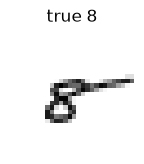

In [20]:
# Which test images does the best model still get wrong?
best_name = summary.loc[summary['test misclassification error'].idxmin(), 'method']
wrong = np.where(pred[best_name] != yte)[0]
print(best_name, '- misclassified test images:', len(wrong))

if len(wrong):
    k_ = min(len(wrong), 10)
    fig, ax = plt.subplots(1, k_, figsize=(1.6*k_, 2), squeeze=False)
    for a, k in zip(ax[0], wrong[:k_]):
        a.imshow(Xte_raw[k].reshape(28, 28), cmap='gray_r'); a.set_title(f'true {5+3*yte[k]}'); a.axis('off')
    plt.show()

**Discussion.**

| Method | Test error (deskew + HOG) | Test error (raw pixels) |
|---|---|---|
| Single tree | 2.20% (39 / 1866) | 3.64% |
| Bagging | 1.13% (21) | 2.09% |
| Random forest | 0.27% (5) | 0.86% |
| Boosting | **0.05% (1)** | 0.48% |

- **Ranking:** boosting < random forest < bagging < single tree, both with and without feature engineering. This is the ordering the theory predicts:
  - *Single tree:* a single pruned tree (here only 32 leaves) has high variance, and its piecewise-constant boundary is coarse.
  - *Bagging:* averaging many unpruned trees cuts the variance roughly in half.
  - *Random forest:* restricting each split to $m=\sqrt{p}\approx 33$ random features decorrelates the trees. The variance of an average of $B$ trees with pairwise correlation $\rho$ is $\rho\sigma^2+(1-\rho)\sigma^2/B$, so lowering $\rho$ removes variance that bagging cannot. This is the largest single improvement.
  - *Boosting:* fitting shallow trees sequentially to the gradient of the log-loss also reduces bias, and with shrinkage, subsampling and CV-chosen early stopping it generalizes best.
- **Feature engineering helps every method** (the error is roughly halved or better). Deskewing removes slant variation that axis-aligned splits model poorly, and HOG encodes stroke orientation. The choice was made with training-set CV before the test set was used.
- **Train-side estimates are consistent with the test errors** (tree: CV 2.85% vs test 2.09%; bagging: CV 1.41% vs 1.13%; random forest: OOB 0.64% vs 0.27%; boosting: CV 0.35% vs 0.05%). The test errors are somewhat lower, partly because more training data is used in the final fits than within each CV fold, and partly by chance: with 1866 test images, a difference of one or two errors is about 0.1 percentage points. The ordering, however, agrees between CV and test.
- The single remaining boosting error is plotted above. These are typically ambiguous or badly written digits.